In [1]:
import os
import sys
import tempfile
from pathlib import Path
from IPython.display import Image, display

# The notebook starts in docs/examples. Keep generated files outside the checkout.
repository = Path.cwd().parents[1]
workspace = tempfile.TemporaryDirectory(prefix="croak-gallery-")
(Path(workspace.name) / "examples").symlink_to(repository / "examples", target_is_directory=True)
sys.path.insert(0, str(repository / "examples"))
os.chdir(workspace.name)

In [2]:
"""Geometric time smearing: what an unmodelled BOXCARS kernel does to a retrieval.

In a non-collinear BOXCARS geometry the three input beams reach the interaction
plane with tilted pulse fronts, so the relative arrival time between arms varies
across the focal spot and the spectrometer averages over it. If the retrieval does
not model that instrument response, the free pulse has to absorb it.

This example, for an example deep-UV mask (1 mm holes, 0.5 mm edge to edge, at
260 nm):

* builds the smearing kernel from the mask geometry alone (the focal length
  cancels, so it never appears),
* synthesises a trace from a known 1 fs pulse *with* the kernel,
* retrieves it three ways — kernel modelled, kernel ignored, kernel strength
  fitted — and reports the duration, rms width and trace error of each,
* sweeps the mask ratio d/D, a controlled change in this reduced model; a real
  instrument can also change its illumination and collection when mask spacing
  changes,
* sweeps the slab thickness, and
* saves the comparison figure.

Every retrieval is run to tight stopping tolerances from two Gaussian starts, and
the lowest-error fit is kept. With the kernel modelled (or its scale fitted), both
starts recover the 1 fs pulse to round-off. With the kernel ignored, the model
cannot reproduce the trace. Its residual trace error is the robust signature: it
stays at 1e-3 to 1e-2, against round-off for the matched fit, and grows steadily
with the mask ratio. The duration is not a robust signature. Without a slab the best
fit puts the blur into broad, low-level temporal wings (the rms width grows about
ninefold) and its FWHM comes out slightly *short*; with a slab the FWHM comes out
long. At some thicknesses the two starts reach the same trace error with FWHMs
several hundredths of a femtosecond apart, so the script prints that spread.

Offsets are quoted as *smeared minus clean*, each retrieved with the same settings
and starts, so a bias common to both fits (such as finite grid sampling) cancels.
It does not cancel the start dependence of the smeared fit, which is a property of
the misspecified model and is reported separately.

Run::

    uv run python examples/example_geometric_smearing.py

Writes ``geometric_smearing.png`` to the working directory. It takes about two
minutes, mostly in the dispersive fits of the thickness sweep.
"""

from __future__ import annotations

import matplotlib
import numpy as np

matplotlib.use("Agg")

# Imported after `matplotlib.use`, which only takes effect before pyplot binds a
# backend -- hence the E402 suppressions.
import matplotlib.pyplot as plt  # noqa: E402 - must follow matplotlib.use above

import croak  # noqa: E402 - imports pyplot transitively; see the note above
from croak.maths import moment, wlfreq  # noqa: E402 - see the note above
from croak.smearing import square_boxcars_kernel  # noqa: E402 - see the note above

# --- an example deep-UV instrument ---------------------------------------------
WAVELENGTH = 260e-9  # carrier (m)
HOLE_DIAMETER = 1.0e-3  # mask hole diameter D (m)
HOLE_SPACING = 0.5e-3  # edge-to-edge gap between adjacent holes (m)
INTERACTION = "pg"  # TG-FROG is retrieved with the PG signal operator

# --- the pulse under test -----------------------------------------------------
# Short enough that a sub-femtosecond blur matters, on a grid fine enough to
# resolve it and a delay axis wide enough for the delay-axis convolution.
TRUE_FWHM = 1.0e-15
GRID_POINTS = 256
TIME_STEP = 0.12e-15
DELAY_SPAN = 12e-15
DELAY_POINTS = 81
# Stopping: the default tolerances end the kernel-ignored fits after a few dozen
# evaluations, far from their minimum (the FWHM still moves by ~0.1 fs). These
# tolerances let L-BFGS run until it stalls; the iteration cap is a safety net.
# An exactly matched model drives R towards round-off (~1e-16), where NLopt's line
# search fails and warns; stopping at TARGET_ERROR ends those fits cleanly first.
# The kernel-ignored fits never get near it.
MAXITERS = 4000
TOLERANCES = {"reltol": 1e-12, "abstol": 1e-15}
TARGET_ERROR = 1e-10
# Gaussian starting pulses (FWHM, s): one short of the truth, one long.
START_WIDTHS = (1.0e-15, 1.6e-15)

# Mask spacings for the mask sweep (m, edge to edge).
SPACINGS = (0.0, 0.5e-3, 1.0e-3, 1.5e-3)
# Slab thicknesses for the thickness sweep (m).
THICKNESSES = (0.0, 10e-6, 20e-6, 40e-6)
MATERIAL = "SiO2"


def kernel_for(spacing: float):
    """Square-BOXCARS kernel for a given edge-to-edge hole spacing."""
    return square_boxcars_kernel(
        INTERACTION,
        hole_diameter=HOLE_DIAMETER,
        hole_spacing=spacing,
        wavelength=WAVELENGTH,
    )


def mask_ratio(spacing: float) -> float:
    """Mask ratio d/D for a given edge-to-edge spacing."""
    return 0.5 * (spacing + HOLE_DIAMETER) / HOLE_DIAMETER


def rms_width(t: np.ndarray, intensity: np.ndarray) -> float:
    """Root-mean-square temporal width (s) of an intensity profile.

    Unlike the FWHM, which only sees the central peak, the rms width weights the
    whole profile by ``t**2`` and so registers energy moved into low-level wings.
    """
    centroid = moment(t, intensity)
    return float(np.sqrt(moment(t - centroid, intensity, 2)))


def banner(text: str) -> None:
    """Print a section heading."""
    print(f"\n{text}\n{'-' * len(text)}")


def main() -> None:
    """Run the three retrievals and the two sweeps."""
    grid = croak.Grid(GRID_POINTS, dt=TIME_STEP)
    ew = croak.gaussian_pulse(grid, TRUE_FWHM)
    delays = np.linspace(-DELAY_SPAN, DELAY_SPAN, DELAY_POINTS)
    omega0 = float(wlfreq(WAVELENGTH))
    starts = [croak.gaussian_pulse(grid, width) for width in START_WIDTHS]

    def retrieve_all(trace, **model) -> list[croak.RetrievalResult]:
        """Retrieve from every start, best (lowest trace error) first.

        Regularisation is off (``reg_amp=0``, ``reg_spectrum=0``) because this is
        a matched, noise-free synthetic comparison: every fit minimises the bare
        trace discrepancy.
        """
        fits = [
            croak.retrieve(
                trace,
                grid.omega,
                delays,
                INTERACTION,
                algorithm="lbfgs-ad",
                guess=start,
                omega0=omega0,
                maxiters=MAXITERS,
                rng=np.random.default_rng(0),
                reg_amp=0,
                reg_spectrum=0,
                progress=False,
                targeterr=TARGET_ERROR,
                **TOLERANCES,
                **model,
            )
            for start in starts
        ]
        return sorted(fits, key=lambda res: res.error)

    def fwhm_of(res: croak.RetrievalResult) -> float:
        """Temporal-intensity FWHM (s) of a retrieved pulse (oversampled profile)."""
        return croak.process_result(res).fwhm_retr

    def fwhm_spread(fits: list[croak.RetrievalResult]) -> float:
        """Max minus min FWHM (s) over the starts: the duration's start dependence."""
        widths = [fwhm_of(res) for res in fits]
        return max(widths) - min(widths)

    kernel = kernel_for(HOLE_SPACING)
    banner("Kernel from the mask geometry")
    print(f"  mask ratio d/D          : {mask_ratio(HOLE_SPACING):.3f}")
    print(f"  sigma_p    (gate split) : {kernel.sigma_p * 1e15:.4f} fs")
    print(f"  sigma_delta (delay)     : {kernel.sigma_delta * 1e15:.4f} fs")
    print(f"  correlation rho         : {kernel.rho:+.4f}")
    print(f"  delay-axis blur FWHM    : {2.3548 * kernel.sigma_delta * 1e15:.4f} fs")

    # The measurement: a trace the instrument would actually record.
    trace = croak.maketrace(grid.omega, delays, ew, INTERACTION, smearing=kernel)

    banner("Retrieving the smeared trace three ways")
    three_ways = {
        "kernel modelled": retrieve_all(trace, smearing=kernel),
        "kernel ignored ": retrieve_all(trace),
        "kernel fitted  ": retrieve_all(trace, smearing=kernel, fit_smearing=True),
    }
    truth = np.abs(grid.ifft(ew)) ** 2
    print(
        f"  truth           : FWHM = {TRUE_FWHM * 1e15:.4f} fs"
        f"   rms = {rms_width(grid.t, truth) * 1e15:.3f} fs"
    )
    for label, fits in three_ways.items():
        best = fits[0]
        extra = "" if best.smear_scale is None else f"  scale = {best.smear_scale:.4f}"
        print(
            f"  {label} : FWHM = {fwhm_of(best) * 1e15:.4f} fs"
            f" (start spread {fwhm_spread(fits) * 1e15:.4f})"
            f"   rms = {rms_width(best.t, best.intensity_t) * 1e15:.3f} fs"
            f"   R = {best.error:.2e}{extra}"
        )

    # --- the mask sweep -------------------------------------------------------
    # In this reduced synthetic model, only the timing kernel changes with mask
    # spacing. A real instrument can also change focal profiles and collection.
    # The trace error the kernel-ignored fit cannot remove grows with the kernel;
    # the FWHM offset depends on the whole trace, not only the kernel width.
    banner("Mask sweep: kernel ignored, versus d/D")
    reference = fwhm_of(
        retrieve_all(croak.maketrace(grid.omega, delays, ew, INTERACTION))[0]
    )
    ratios, mask_errors = [], []
    for spacing in SPACINGS:
        k = kernel_for(spacing)
        fits = retrieve_all(
            croak.maketrace(grid.omega, delays, ew, INTERACTION, smearing=k)
        )
        ratios.append(mask_ratio(spacing))
        mask_errors.append(fits[0].error)
        print(
            f"  d/D = {ratios[-1]:.3f}  sigma_delta = {k.sigma_delta * 1e15:.4f} fs"
            f"   R = {fits[0].error:.2e}"
            f"   FWHM offset = {(fwhm_of(fits[0]) - reference) * 1e15:+.4f} fs"
            f" (start spread {fwhm_spread(fits) * 1e15:.4f})"
        )

    # --- the thickness sweep --------------------------------------------------
    # The kernel itself is thickness-independent: the pulse-front tilts are fixed
    # before the medium and the longitudinal walk-off inside a thin slab is far
    # below a femtosecond, so the same (p, delta) applies at every depth node. The
    # duration offset it *induces* in a kernel-ignored fit is a different quantity
    # and is not constant — the trace's sensitivity to the input duration changes
    # with the slab — so a flat offset across thicknesses is no test for smearing.
    banner("Thickness sweep: kernel ignored, smeared minus clean")
    thickness_offsets, start_offsets = [], []
    for thickness in THICKNESSES:
        slab = (
            {"material": MATERIAL, "thickness": thickness, "npoints": 20}
            if thickness > 0
            else {}
        )
        smeared = retrieve_all(
            croak.maketrace(
                grid.omega,
                delays,
                ew,
                INTERACTION,
                smearing=kernel,
                omega0=omega0,
                **slab,
            ),
            **slab,
        )
        clean = retrieve_all(
            croak.maketrace(grid.omega, delays, ew, INTERACTION, omega0=omega0, **slab),
            **slab,
        )
        clean_fwhm = fwhm_of(clean[0])
        thickness_offsets.append(fwhm_of(smeared[0]) - clean_fwhm)
        start_offsets.append([fwhm_of(res) - clean_fwhm for res in smeared])
        print(
            f"  L = {thickness * 1e6:5.1f} um   R = {smeared[0].error:.2e}"
            f" (clean {clean[0].error:.1e})"
            f"   FWHM offset = {thickness_offsets[-1] * 1e15:+.4f} fs"
            f" (start spread {fwhm_spread(smeared) * 1e15:.4f})"
        )

    # --- figure ---------------------------------------------------------------
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    # Log scale: the kernel-ignored fit differs from the truth mainly in its wings.
    for label, style in (("kernel modelled", "-"), ("kernel ignored ", "--")):
        best = three_ways[label][0]
        intensity = best.intensity_t / best.intensity_t.max()
        axes[0].semilogy(
            best.t * 1e15,
            intensity,
            style,
            label=f"{label.strip()} ({fwhm_of(best) * 1e15:.3f} fs)",
        )
    axes[0].semilogy(
        grid.t * 1e15,
        truth / truth.max(),
        "k:",
        lw=1,
        label=f"truth ({TRUE_FWHM * 1e15:.3f} fs)",
    )
    axes[0].set(
        xlabel="time (fs)",
        ylabel="intensity (norm.)",
        xlim=(-10, 10),
        ylim=(1e-5, 2),
        title="Retrieved pulse",
    )
    axes[0].legend(fontsize=7, loc="upper right")

    axes[1].semilogy(ratios, mask_errors, "o-")
    axes[1].set(
        xlabel="mask ratio $d/D$",
        ylabel="trace error R, kernel ignored",
        title="Mask sweep",
    )
    axes[1].grid(alpha=0.3)

    thickness_um = np.asarray(THICKNESSES) * 1e6
    axes[2].plot(
        thickness_um, np.asarray(thickness_offsets) * 1e15, "s-", label="best R"
    )
    for thickness, offsets in zip(thickness_um, start_offsets, strict=True):
        axes[2].plot(
            [thickness] * len(offsets),
            np.asarray(offsets) * 1e15,
            "o",
            mfc="none",
            color="C1",
            label="each start" if thickness == thickness_um[0] else None,
        )
    axes[2].axhline(0, color="k", lw=0.8)
    axes[2].set(
        xlabel="slab thickness (µm)",
        ylabel="FWHM offset (fs), kernel ignored",
        title="Thickness sweep",
    )
    axes[2].legend(fontsize=8)
    axes[2].grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig("geometric_smearing.png", dpi=150)
    print("\nwrote geometric_smearing.png")


if __name__ == "__main__":
    main()



Kernel from the mask geometry
-----------------------------
  mask ratio d/D          : 0.750
  sigma_p    (gate split) : 0.3196 fs
  sigma_delta (delay)     : 0.3573 fs
  correlation rho         : +0.4472
  delay-axis blur FWHM    : 0.8414 fs

Retrieving the smeared trace three ways
---------------------------------------


  truth           : FWHM = 1.0000 fs   rms = 0.425 fs
  kernel modelled : FWHM = 1.0000 fs (start spread 0.0000)   rms = 0.425 fs   R = 3.41e-16
  kernel ignored  : FWHM = 0.9347 fs (start spread 0.0000)   rms = 3.772 fs   R = 4.96e-03
  kernel fitted   : FWHM = 1.0000 fs (start spread 0.0000)   rms = 0.425 fs   R = 3.41e-16  scale = 1.0000

Mask sweep: kernel ignored, versus d/D
--------------------------------------


  d/D = 0.500  sigma_delta = 0.2382 fs   R = 2.39e-03   FWHM offset = -0.0192 fs (start spread 0.0012)


  d/D = 0.750  sigma_delta = 0.3573 fs   R = 4.96e-03   FWHM offset = -0.0654 fs (start spread 0.0000)


  d/D = 1.000  sigma_delta = 0.4764 fs   R = 8.02e-03   FWHM offset = -0.1092 fs (start spread 0.0001)


  d/D = 1.250  sigma_delta = 0.5955 fs   R = 1.13e-02   FWHM offset = -0.0464 fs (start spread 0.0002)

Thickness sweep: kernel ignored, smeared minus clean
----------------------------------------------------


  L =   0.0 um   R = 4.96e-03 (clean 4.5e-16)   FWHM offset = -0.0654 fs (start spread 0.0000)


  L =  10.0 um   R = 1.25e-03 (clean 4.4e-16)   FWHM offset = +0.2215 fs (start spread 0.0580)


  L =  20.0 um   R = 9.23e-04 (clean 1.2e-15)   FWHM offset = +0.1052 fs (start spread 0.0006)


  L =  40.0 um   R = 9.05e-04 (clean 2.7e-15)   FWHM offset = +0.0841 fs (start spread 0.0769)

wrote geometric_smearing.png


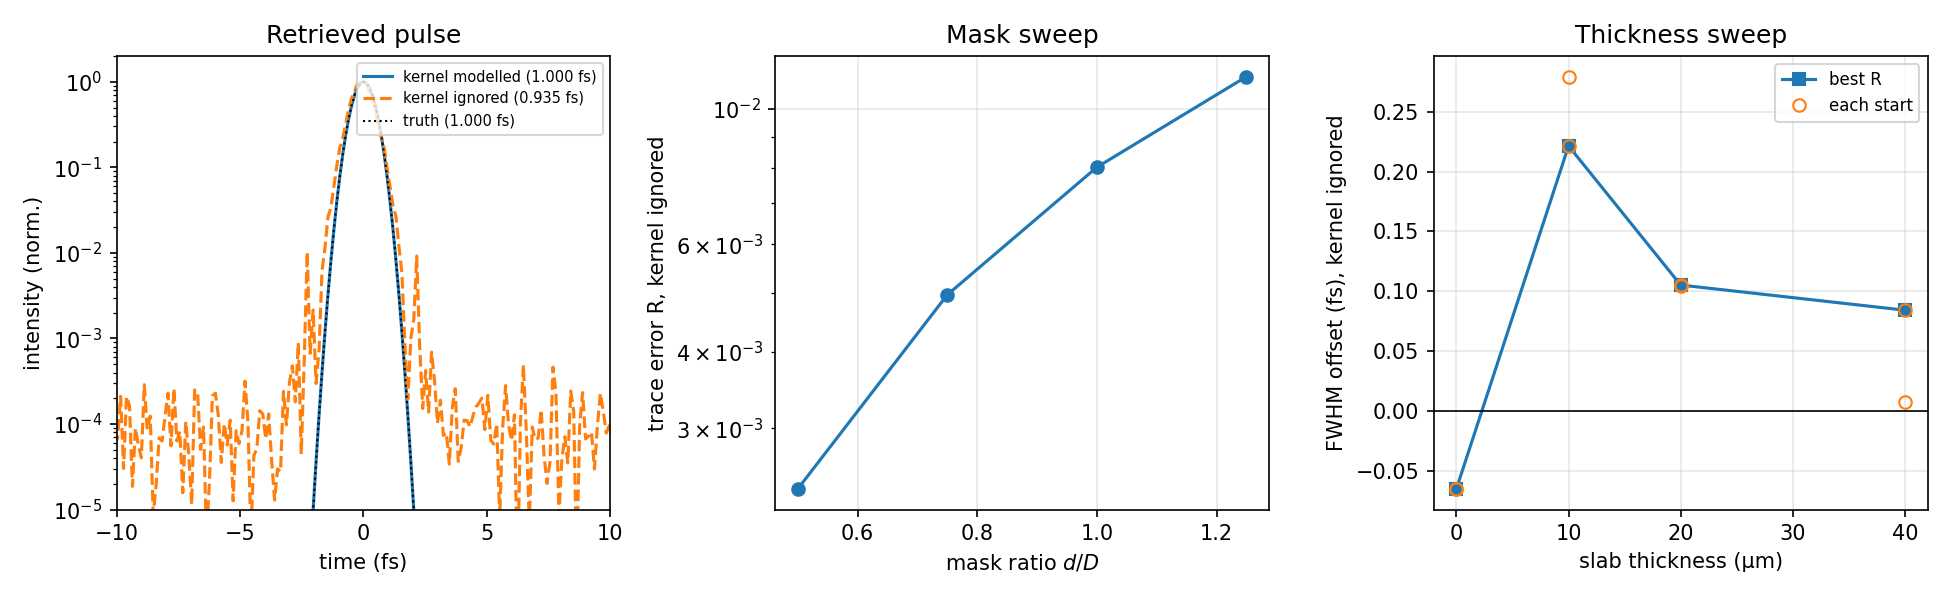

In [3]:
display(Image(filename="geometric_smearing.png"))